In [1]:
%pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, GridSearchCV )

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

RANDOM_STATE = 42



In [3]:
df = pd.read_csv("Dataset/cleaned_cervical_data.csv")

In [4]:
df.shape

(858, 25)

In [5]:
df

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs:vulvo-perineal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:HIV,STDs:Hepatitis B,STDs:HPV,STDs: Number of diagnosis,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.0,0.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
853,34,3.0,18.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
854,32,2.0,19.0,1.0,0.0,0.0,0.0,1.0,8.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
855,25,2.0,17.0,0.0,0.0,0.0,0.0,1.0,0.08,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
856,33,2.0,24.0,2.0,0.0,0.0,0.0,1.0,0.08,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0


In [6]:
counts = df['Biopsy'].value_counts()
print(counts)

Biopsy
0    803
1     55
Name: count, dtype: int64


In [7]:
percentages = (df['Biopsy'].value_counts(normalize=True) * 100).round(2)
print(percentages)

Biopsy
0    93.59
1     6.41
Name: proportion, dtype: float64


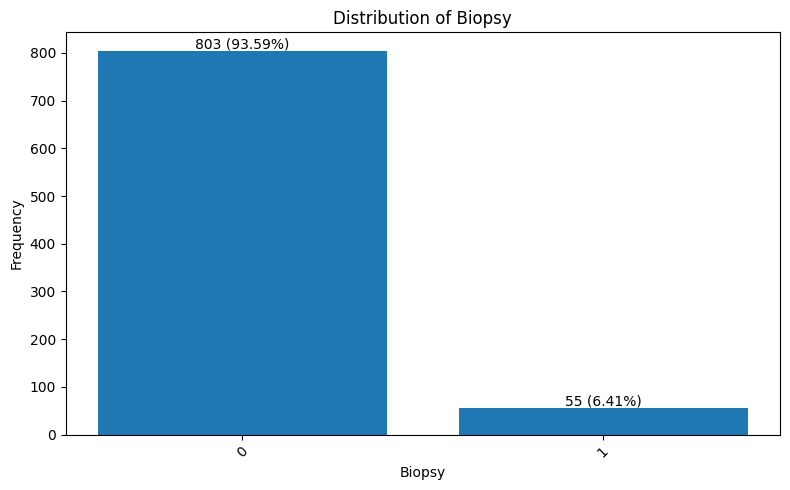

In [8]:
# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(counts.index.astype(str), counts.values)

# Combine count and percentage into labels
labels = [f'{count} ({percent}%)' for count, percent in zip(counts, percentages)]

# Add labels on top of bars
for bar, label in zip(bars, labels):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        label,
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.xlabel('Biopsy')
plt.ylabel('Frequency')
plt.title('Distribution of Biopsy')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

According to the dataset, there is class imbalance because there are more patients of category 0 (negative: no cervical cancer confirmed) than those of category 1


In [9]:
df.isnull().sum()[df.isnull().sum() > 0]

Number of sexual partners              26
First sexual intercourse                9
Num of pregnancies                     56
Smokes                                 13
Smokes (years)                         13
Smokes (packs/year)                    13
Hormonal Contraceptives               108
Hormonal Contraceptives (years)       108
IUD                                   117
IUD (years)                           117
STDs                                  105
STDs (number)                         105
STDs:condylomatosis                   105
STDs:vaginal condylomatosis           105
STDs:vulvo-perineal condylomatosis    105
STDs:syphilis                         105
STDs:pelvic inflammatory disease      105
STDs:genital herpes                   105
STDs:molluscum contagiosum            105
STDs:HIV                              105
STDs:Hepatitis B                      105
STDs:HPV                              105
dtype: int64

## Checking missingness partterns vs target (Biopsy)

***The goal here is to understand how missing data relate to the outcome, preserve useful observations, and evaluate whether missingness itself contributes predictive information without assuming it reflects a causal relationship.***

This is to check whether the patients with missing STD/IUD/contraceptive answers have a very different cancer (Biopsy=1) rate compared to those without missing.

This tells us whether the missingness itself carries predictive signal (not Missing Completely at Random) or not.

In [10]:
# How many rows have at least one missing value?
print("Rows with >=1 missing value:", df.isnull().any(axis=1).sum(), "out of", len(df))

# Does missingness correlate with Biopsy? (Checking the main missing blocks)
for col in ['IUD', 'Hormonal Contraceptives', 'STDs', 'Num of pregnancies']:
    print(f"\nBiopsy rate when {col} is missing vs present:")
    print(df.groupby(df[col].isnull())['Biopsy'].agg(['count', 'mean']))

Rows with >=1 missing value: 190 out of 858

Biopsy rate when IUD is missing vs present:
       count      mean
IUD                   
False    741  0.070175
True     117  0.025641

Biopsy rate when Hormonal Contraceptives is missing vs present:
                         count      mean
Hormonal Contraceptives                 
False                      750  0.073333
True                       108  0.000000

Biopsy rate when STDs is missing vs present:
       count      mean
STDs                  
False    753  0.070385
True     105  0.019048

Biopsy rate when Num of pregnancies is missing vs present:
                    count     mean
Num of pregnancies                
False                 802  0.05985
True                   56  0.12500


In [11]:
missingness = df.isnull().mean().mul(100).sort_values(
    ascending=False
)

display(missingness[missingness > 0].round(2))

IUD                                   13.64
IUD (years)                           13.64
Hormonal Contraceptives               12.59
Hormonal Contraceptives (years)       12.59
STDs:vulvo-perineal condylomatosis    12.24
STDs (number)                         12.24
STDs                                  12.24
STDs:vaginal condylomatosis           12.24
STDs:condylomatosis                   12.24
STDs:pelvic inflammatory disease      12.24
STDs:genital herpes                   12.24
STDs:molluscum contagiosum            12.24
STDs:HIV                              12.24
STDs:Hepatitis B                      12.24
STDs:HPV                              12.24
STDs:syphilis                         12.24
Num of pregnancies                     6.53
Number of sexual partners              3.03
Smokes (packs/year)                    1.52
Smokes                                 1.52
Smokes (years)                         1.52
First sexual intercourse               1.05
dtype: float64

The exploratory analysis identified differences in biopsy outcome rates between records with missing and non-missing values for selected variables. For example, records with missing hormonal contraceptive information had a different observed biopsy-positive rate from records where this information was available. These findings suggest that missingness patterns may be associated with the observed outcome. However, this analysis alone cannot establish whether the missing data are MCAR, MAR or MNAR. Therefore, incomplete observations were retained and missing values were handled using appropriate imputation techniques within the training pipeline.

## Checking duplicates and Constant (Zero-Variance) Columns

***The goal here is to identify redundant records and variables with little or no predictive value before model development.***

This is to:
1) *Duplicate rows*: Identify repeated records to avoid having the same observations in both training and testing sets, which could lead to misleadingly good model performance.

2) *Constant columns*: Identify variables with only one unique value (e.g., STDs:AIDS or STDs:cervical condylomatosis) because they provide no useful information for distinguishing between outcome groups.

3) *Near-constant columns*: Identify variables with very few positive cases (e.g., only 1 or 2 cases out of 858) because they may contribute little to model learning and could make the model less reliable.

In [12]:
print("Exact duplicate rows:", df.duplicated().sum())

print("\nNumber of unique values per column (sorted ascending):")
print(df.nunique(dropna=True).sort_values())

Exact duplicate rows: 26

Number of unique values per column (sorted ascending):
Hormonal Contraceptives                2
Smokes                                 2
STDs                                   2
STDs:vulvo-perineal condylomatosis     2
STDs:condylomatosis                    2
STDs:vaginal condylomatosis            2
IUD                                    2
STDs:syphilis                          2
Biopsy                                 2
STDs:HPV                               2
STDs:Hepatitis B                       2
STDs:HIV                               2
STDs:molluscum contagiosum             2
STDs:genital herpes                    2
STDs:pelvic inflammatory disease       2
STDs: Number of diagnosis              4
STDs (number)                          5
Num of pregnancies                    11
Number of sexual partners             12
First sexual intercourse              21
IUD (years)                           26
Smokes (years)                        30
Hormonal Contrace

26 exact duplicate rows exist. There is need to inspect/remove duplicates before splitting, or else, the exact same patient profile can end up in both training and test sets, artificially inflating RF/DT accuracy.


Several STD columns have almost zero positives (1–4 cases out of 753)

- STDs:pelvic inflammatory disease, STDs:genital herpes, STDs:molluscum contagiosum, and STDs:Hepatitis B each have only 1 positive case (0.001328 × 753 ≈ 1).

- STDs:HPV has only 2 cases, and STDs:vaginal condylomatosis has only 4 cases.

## Inspecting duplicates further

In [13]:
# Inspect duplicates & check how features correlate with Biopsy and each other
print("Biopsy breakdown among exact duplicate rows:")
print(df[df.duplicated(keep=False)]['Biopsy'].value_counts())

print("\nTop correlations with Biopsy:")
print(df.corr()['Biopsy'].sort_values(ascending=False))

# Check highly collinear feature pairs (|r| > 0.75)
corr_matrix = df.drop(columns=['Biopsy']).corr().abs()
high_corr = [
    (corr_matrix.columns[i], corr_matrix.columns[j], round(corr_matrix.iloc[i, j], 3))
    for i in range(len(corr_matrix.columns))
    for j in range(i + 1, len(corr_matrix.columns))
    if corr_matrix.iloc[i, j] > 0.75
]
print("\nHighly correlated feature pairs (|r| > 0.75):")
for pair in high_corr:
    print(pair)

Biopsy breakdown among exact duplicate rows:
Biopsy
0    46
1     2
Name: count, dtype: int64

Top correlations with Biopsy:
Biopsy                                1.000000
STDs:genital herpes                   0.132526
STDs:HIV                              0.126880
STDs                                  0.109099
STDs (number)                         0.098347
STDs: Number of diagnosis             0.097449
STDs:vulvo-perineal condylomatosis    0.088902
STDs:condylomatosis                   0.086390
Hormonal Contraceptives (years)       0.079388
Smokes (years)                        0.062044
Age                                   0.055956
IUD                                   0.053194
Num of pregnancies                    0.046416
IUD (years)                           0.033275
Smokes                                0.029356
Smokes (packs/year)                   0.024882
First sexual intercourse              0.008324
Hormonal Contraceptives               0.007750
Number of sexual partners    

In [14]:
df = df.drop_duplicates().copy()


In [15]:
df.shape

(832, 25)

## Feature selection and feature engineering

In [16]:

# Diagnostic and screening variables unavailable at the intended
# pre-screening prediction stage
leakage_columns = [
    "Hinselmann",
    "Schiller",
    "Citology",
    "Dx",
    "Dx:Cancer",
    "Dx:CIN",
    "Dx:HPV"
]

# Remove only those columns that are present
columns_to_remove = [
    col for col in leakage_columns
    if col in df.columns
]

df = df.drop(columns=columns_to_remove)

print("Excluded leakage-related columns:")
print(columns_to_remove)

print("\nUpdated dataset shape:", df.shape)

# Verify that none remain
remaining_leakage = [
    col for col in leakage_columns
    if col in df.columns
]

assert len(remaining_leakage) == 0, (
    f"Potential leakage columns remain: {remaining_leakage}"
)

print("Leakage check passed.")


Excluded leakage-related columns:
[]

Updated dataset shape: (832, 25)
Leakage check passed.


In [17]:
#  Separate features (X) and target (y)
X = df.drop(columns=['Biopsy'])
y = df['Biopsy']


Constant features:
[]

Predictor shape after constant-feature removal: (832, 24)


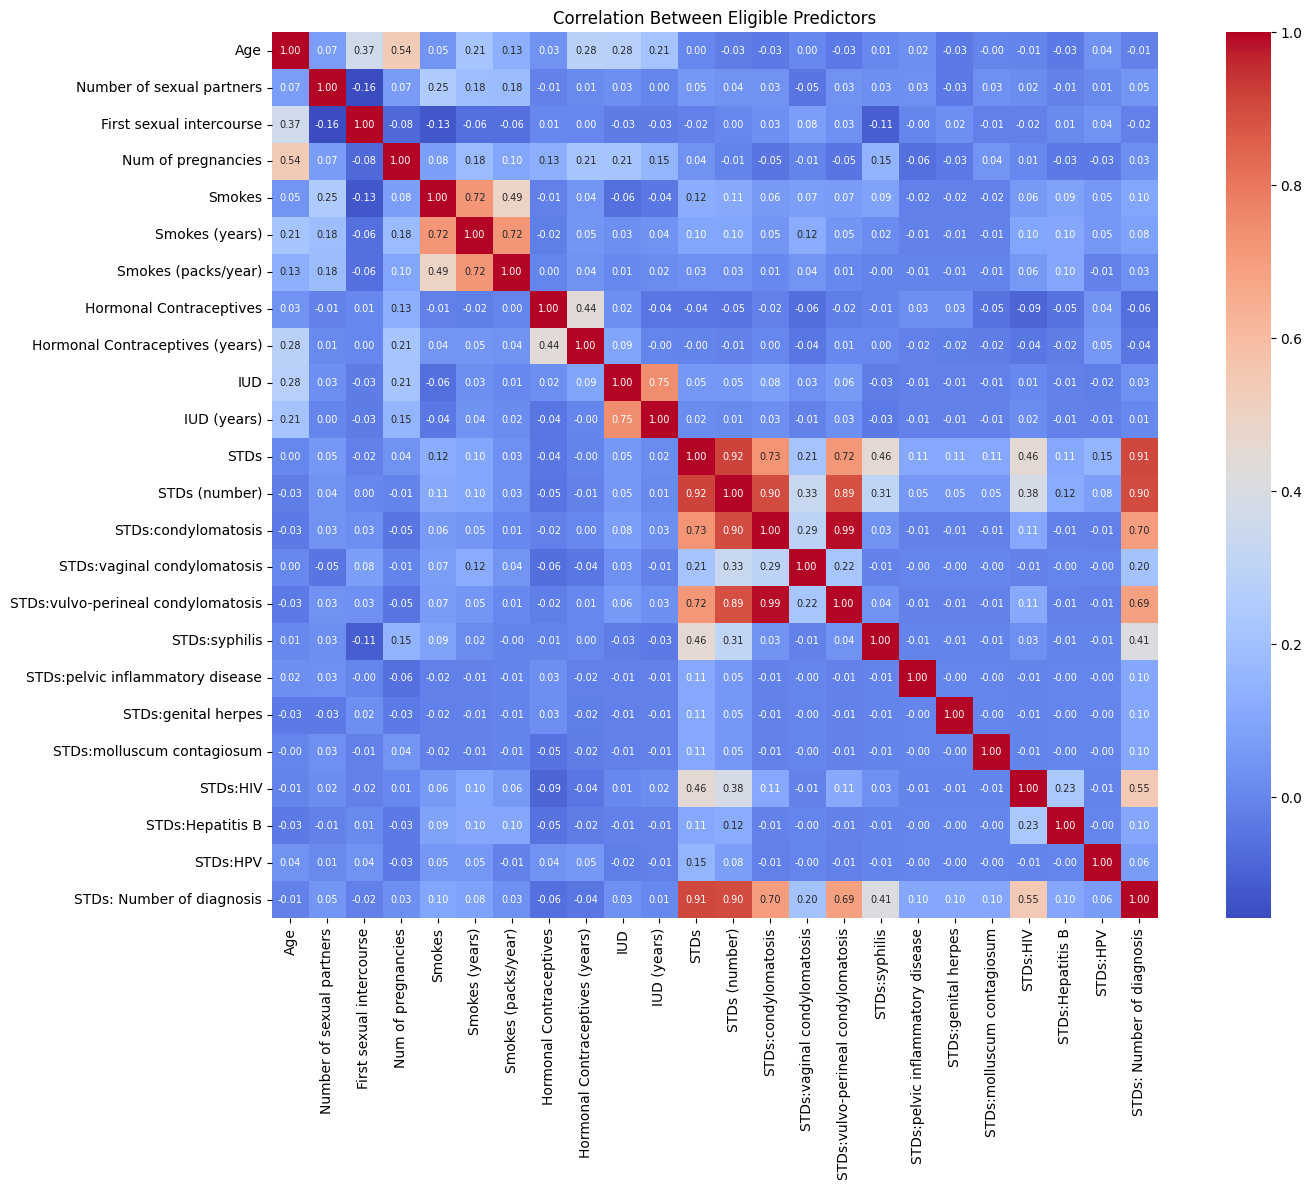


Highly correlated predictor pairs (absolute correlation >= 0.85):


STDs:condylomatosis  STDs:vulvo-perineal condylomatosis    0.987853
STDs                 STDs (number)                         0.918367
                     STDs: Number of diagnosis             0.906390
STDs (number)        STDs:condylomatosis                   0.899351
                     STDs: Number of diagnosis             0.896945
                     STDs:vulvo-perineal condylomatosis    0.890516
dtype: float64

In [18]:

# Check features with zero variance
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

print("Constant features:")
print(constant_columns)

# Remove only constant features
X = X.drop(columns=constant_columns)

print("\nPredictor shape after constant-feature removal:", X.shape)

# Examine correlations among predictors
correlation_matrix = X.corr(numeric_only=True)

plt.figure(figsize=(16, 12))


sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
           cbar=True, annot_kws={"size": 7}, square=True)
            
plt.title("Correlation Between Eligible Predictors")
plt.tight_layout()
plt.show()

# Identify highly correlated pairs for investigation
corr_pairs = correlation_matrix.abs().where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

high_corr_pairs = corr_pairs[corr_pairs >= 0.85].sort_values(
    ascending=False
)

print("\nHighly correlated predictor pairs (absolute correlation >= 0.85):")
display(high_corr_pairs)


In [19]:

# Numerical/count/duration features
numerical_candidates = [
    "Age",
    "Number of sexual partners",
    "First sexual intercourse",
    "Num of pregnancies",
    "Smokes (years)",
    "Smokes (packs/year)",
    "Hormonal Contraceptives (years)",
    "IUD (years)",
    "STDs (number)",
    "STDs: Number of diagnosis"
]

# Retain only numerical candidates present in the dataset
num_cols = [
    col for col in numerical_candidates
    if col in X.columns
]

# Remaining columns are binary indicators in this dataset
bin_cols = [
    col for col in X.columns
    if col not in num_cols
]

print("Numerical features:")
print(num_cols)

print("\nBinary features:")
print(bin_cols)

print("\nNumber of numerical features:", len(num_cols))
print("Number of binary features:", len(bin_cols))

# Verify that all features are assigned
assert set(num_cols).union(set(bin_cols)) == set(X.columns)
assert set(num_cols).isdisjoint(set(bin_cols))


Numerical features:
['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives (years)', 'IUD (years)', 'STDs (number)', 'STDs: Number of diagnosis']

Binary features:
['Smokes', 'Hormonal Contraceptives', 'IUD', 'STDs', 'STDs:condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:vulvo-perineal condylomatosis', 'STDs:syphilis', 'STDs:pelvic inflammatory disease', 'STDs:genital herpes', 'STDs:molluscum contagiosum', 'STDs:HIV', 'STDs:Hepatitis B', 'STDs:HPV']

Number of numerical features: 10
Number of binary features: 14


In [20]:
df.describe()

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs:vulvo-perineal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:HIV,STDs:Hepatitis B,STDs:HPV,STDs: Number of diagnosis,Biopsy
count,832.000000,807.000000,823.000000,776.000000,819.000000,819.000000,819.000000,729.000000,729.000000,720.000000,...,732.000000,732.000000,732.000000,732.000000,732.000000,732.000000,732.000000,732.000000,832.000000,832.000000
mean,27.060096,2.555143,17.014581,2.309278,0.150183,1.258443,0.467529,0.654321,2.312393,0.115278,...,0.058743,0.024590,0.001366,0.001366,0.001366,0.024590,0.001366,0.002732,0.090144,0.064904
std,8.476697,1.678686,2.802029,1.456365,0.357469,4.147616,2.260230,0.475916,3.799102,0.319579,...,0.235304,0.154978,0.036961,0.036961,0.036961,0.154978,0.036961,0.052235,0.306840,0.246504
min,13.000000,1.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,21.000000,2.000000,15.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,26.000000,2.000000,17.000000,2.000000,0.000000,0.000000,0.000000,1.000000,0.500000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,32.000000,3.000000,18.000000,3.000000,0.000000,0.000000,0.000000,1.000000,3.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,84.000000,28.000000,32.000000,11.000000,1.000000,37.000000,37.000000,1.000000,30.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000


## Split the data and build preprocessing pipelines

In [21]:
# Stratified 70/15/15 split to preserve the ~6.4% positive class ratio in both sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, 
    test_size=0.30, 
    stratify=y, 
    random_state=RANDOM_STATE
)

X_test, X_val, y_test, y_val= train_test_split(
    X_temp,y_temp,
    test_size=0.50,
    stratify= y_temp,
    random_state= RANDOM_STATE
    )


In [22]:

# Numerical preprocessing for Logistic Regression
numeric_preprocessor_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Binary preprocessing for Logistic Regression
binary_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# Combine numerical and binary preprocessing
preprocessor_lr = ColumnTransformer([
    ("numerical", numeric_preprocessor_lr, num_cols),
    ("binary", binary_preprocessor, bin_cols)
])

# For tree-based models, scaling is not necessary
numeric_preprocessor_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_tree = ColumnTransformer([
    ("numerical", numeric_preprocessor_tree, num_cols),
    ("binary", binary_preprocessor, bin_cols)
])

print("Preprocessing pipelines created.")


Preprocessing pipelines created.


In [23]:
X_train_binary = pd.DataFrame(
    binary_preprocessor.fit_transform(X_train[bin_cols]),
    columns=bin_cols,
    index=X_train.index
)

print("Missing values:", X_train_binary.isnull().sum().sum())

Missing values: 0


In [24]:
from sklearn.feature_selection import chi2

chi_scores, p_values = chi2(
    X_train_binary,
    y_train
)

chi_results = pd.DataFrame({
    "Feature": bin_cols,
    "Chi2 Score": chi_scores,
    "P-value": p_values
})

chi_results = chi_results.sort_values(
    by="Chi2 Score",
    ascending=False
)

display(chi_results.round(4))

,Feature,Chi2 Score,P-value
9,STDs:genital herpes,14.3158,0.0002
3,STDs,9.0932,0.0026
11,STDs:HIV,6.7083,0.0096
6,STDs:vulvo-perineal condylomatosis,6.3594,0.0117
4,STDs:condylomatosis,5.8874,0.0152
2,IUD,1.7288,0.1886
7,STDs:syphilis,0.8382,0.3599
0,Smokes,0.4933,0.4825
5,STDs:vaginal condylomatosis,0.2096,0.6471
13,STDs:HPV,0.1397,0.7086


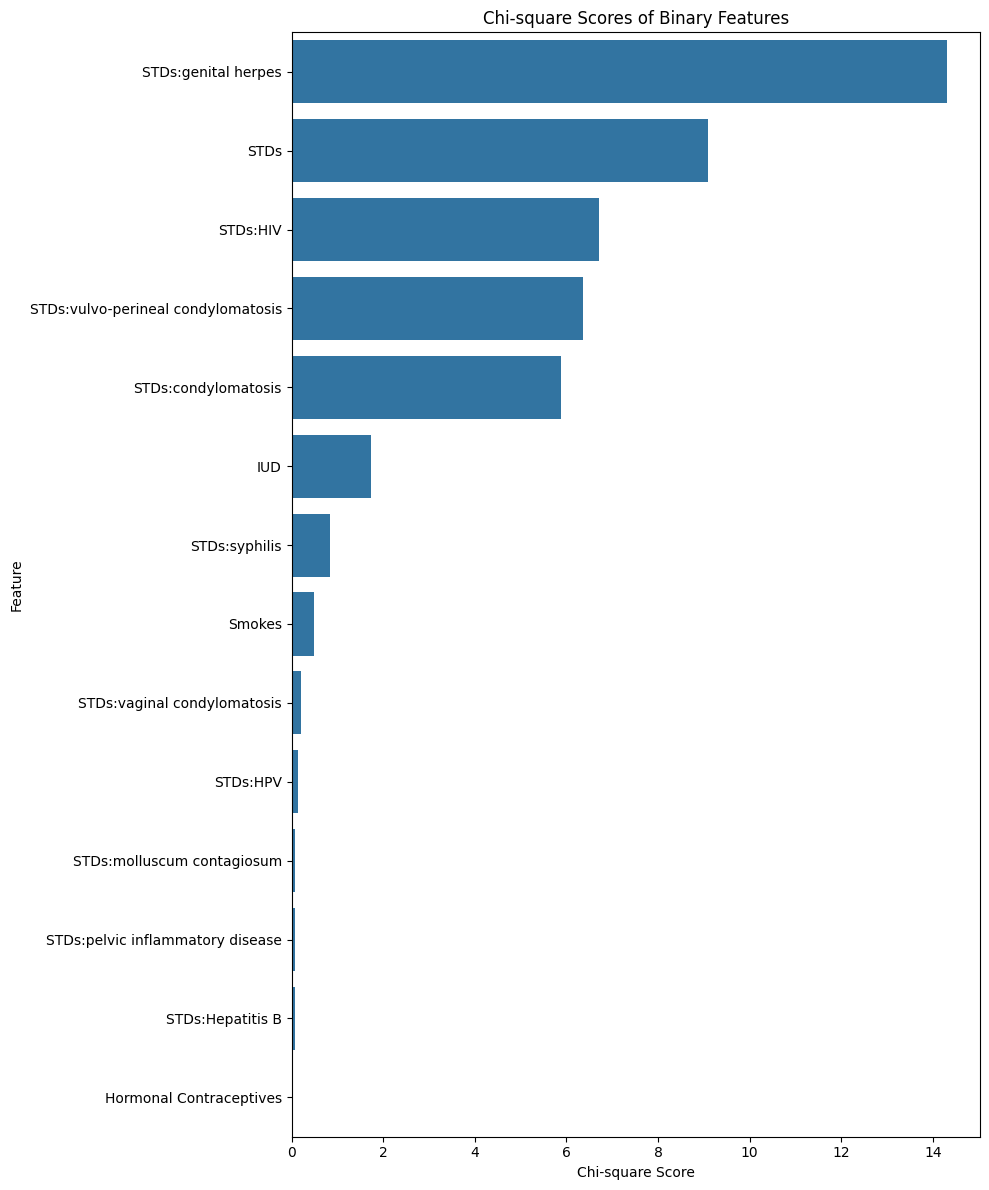

In [25]:

plt.figure(figsize=(10, 12))

sns.barplot(
    data=chi_results,
    x="Chi2 Score",
    y="Feature"
)

plt.title("Chi-square Scores of Binary Features")
plt.xlabel("Chi-square Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [26]:
# Features with zero variance
constant_features = [
    "STDs:genital herpes",
    "STDs:molluscum contagiosum"
]

# Drop from training, validation and testing datasets
X_train = X_train.drop(columns=constant_features)
X_val = X_val.drop(columns=constant_features)
X_test = X_test.drop(columns=constant_features)

print("Removed constant features:", constant_features)
print("Remaining training features:", X_train.shape[1])

Removed constant features: ['STDs:genital herpes', 'STDs:molluscum contagiosum']
Remaining training features: 22


Two features, STDs:genital herpes and STDs:molluscum contagiosum, were identified as having zero variance in the training dataset. All 517 observed records for each feature contained a value of zero, while 83 observations were missing. Since neither feature contained an observed positive case, they could not provide discriminatory information for the classification task. The features were therefore excluded from the model development dataset.

In [27]:
# Identify features with only one unique observed value
constant_cols = [
    col for col in X_train.columns
    if X_train[col].nunique(dropna=True) <= 1
]

print("Constant features:", constant_cols)

Constant features: []


In [28]:
# Features excluded from the primary model
excluded_features = [
    "Hinselmann",
    "Schiller",
    "Citology",
    "Dx:Cancer",
    "Dx:CIN",
    "Dx:HPV",
    "Dx",
    "STDs:genital herpes",
    "STDs:molluscum contagiosum"
]

# Remove excluded features from all datasets
X_train = X_train.drop(columns=excluded_features, errors="ignore")
X_val = X_val.drop(columns=excluded_features, errors="ignore")
X_test = X_test.drop(columns=excluded_features, errors="ignore")

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nRemaining features:")
print(X_train.columns.tolist())

Training shape: (582, 22)
Validation shape: (125, 22)
Testing shape: (125, 22)

Remaining features:
['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives', 'Hormonal Contraceptives (years)', 'IUD', 'IUD (years)', 'STDs', 'STDs (number)', 'STDs:condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:vulvo-perineal condylomatosis', 'STDs:syphilis', 'STDs:pelvic inflammatory disease', 'STDs:HIV', 'STDs:Hepatitis B', 'STDs:HPV', 'STDs: Number of diagnosis']


In [29]:
numerical_candidates = [
    "Age",
    "Number of sexual partners",
    "First sexual intercourse",
    "Num of pregnancies",
    "Smokes (years)",
    "Smokes (packs/year)",
    "Hormonal Contraceptives (years)",
    "IUD (years)",
    "STDs (number)",
    "STDs: Number of diagnosis"
]

num_cols = [
    col for col in numerical_candidates
    if col in X_train.columns
]

bin_cols = [
    col for col in X_train.columns
    if col not in num_cols
]

print("Numerical features:")
print(num_cols)

print("\nBinary features:")
print(bin_cols)

print("\nTotal numerical:", len(num_cols))
print("Total binary:", len(bin_cols))
print("Total predictors:", len(num_cols) + len(bin_cols))

Numerical features:
['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives (years)', 'IUD (years)', 'STDs (number)', 'STDs: Number of diagnosis']

Binary features:
['Smokes', 'Hormonal Contraceptives', 'IUD', 'STDs', 'STDs:condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:vulvo-perineal condylomatosis', 'STDs:syphilis', 'STDs:pelvic inflammatory disease', 'STDs:HIV', 'STDs:Hepatitis B', 'STDs:HPV']

Total numerical: 10
Total binary: 12
Total predictors: 22


In [30]:
for col in bin_cols:
    values = set(X_train[col].dropna().unique())

    if not values.issubset({0, 1}):
        print(f"{col}: Unexpected values {values}")

In [31]:
X_train[num_cols].info()

<class 'pandas.core.frame.DataFrame'>
Index: 582 entries, 203 to 19
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Age                              582 non-null    int64  
 1   Number of sexual partners        567 non-null    float64
 2   First sexual intercourse         576 non-null    float64
 3   Num of pregnancies               542 non-null    float64
 4   Smokes (years)                   574 non-null    float64
 5   Smokes (packs/year)              574 non-null    float64
 6   Hormonal Contraceptives (years)  517 non-null    float64
 7   IUD (years)                      512 non-null    float64
 8   STDs (number)                    518 non-null    float64
 9   STDs: Number of diagnosis        582 non-null    int64  
dtypes: float64(8), int64(2)
memory usage: 50.0 KB


In [32]:
# Check skewness of all numerical columns using ONLY the training set
skew_values = X_train[num_cols].skew().sort_values(ascending=False)

print("Skewness of Numerical Features (X_train):")
print(skew_values.round(3))

# Flag highly right-skewed features (common rule of thumb: skewness > 1.0)
highly_skewed = skew_values[skew_values > 1.0].index.tolist()
print("\nHighly right-skewed features (skew > 1.0):")
print(highly_skewed)

Skewness of Numerical Features (X_train):
Smokes (packs/year)                8.700
Number of sexual partners          5.980
IUD (years)                        5.073
Smokes (years)                     4.387
STDs: Number of diagnosis          4.043
STDs (number)                      3.489
Hormonal Contraceptives (years)    2.775
First sexual intercourse           1.612
Num of pregnancies                 1.257
Age                                1.249
dtype: float64

Highly right-skewed features (skew > 1.0):
['Smokes (packs/year)', 'Number of sexual partners', 'IUD (years)', 'Smokes (years)', 'STDs: Number of diagnosis', 'STDs (number)', 'Hormonal Contraceptives (years)', 'First sexual intercourse', 'Num of pregnancies', 'Age']


In [33]:
# Numerical preprocessing for Logistic Regression
numeric_preprocessor_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Binary preprocessing
binary_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# Preprocessing for Logistic Regression
preprocessor_lr = ColumnTransformer([
    ("numerical", numeric_preprocessor_lr, num_cols),
    ("binary", binary_preprocessor, bin_cols)
])

# Numerical preprocessing for tree-based models
numeric_preprocessor_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for Decision Tree and Random Forest
preprocessor_tree = ColumnTransformer([
    ("numerical", numeric_preprocessor_tree, num_cols),
    ("binary", binary_preprocessor, bin_cols)
])


## Model development and comparison

In [34]:

models = {
    "Logistic Regression": Pipeline([
        ("preprocessing", preprocessor_lr),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=RANDOM_STATE,
            solver="liblinear"
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessing", preprocessor_tree),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=4,
            min_samples_leaf=5,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessing", preprocessor_tree),
        ("model", RandomForestClassifier(
            class_weight="balanced",
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=3,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Three baseline models created.")


Three baseline models created.


In [35]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


In [36]:
results = []

for name, model in models.items():

    # Predict classes
    y_pred = model.predict(X_val)

    # Predict probabilities for positive class
    y_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC (AP)": average_precision_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (AP)
0,Logistic Regression,0.744,0.1250,0.50,0.2000,0.6261,0.1229
1,Decision Tree,0.608,0.0816,0.50,0.1404,0.5892,0.1695
2,Random Forest,0.944,0.6667,0.25,0.3636,0.7682,0.3417


In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__penalty": ["l1", "l2"]
    },

    "Decision Tree": {
        "model__max_depth": [2, 3, 4, 5, None],
        "model__min_samples_leaf": [3, 5, 10, 15]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [3, 5, 7, None],
        "model__min_samples_leaf": [2, 3, 5, 10]
    }
}

best_models = {}
tuning_results = []

for name, pipeline in models.items():

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV Average Precision": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df.sort_values(
        by="Best CV Average Precision",
        ascending=False
    )
)


,Model,Best CV Average Precision,Best Parameters
2,Random Forest,0.215378,"{'model__max_depth': None, 'model__min_samples..."
0,Logistic Regression,0.158509,"{'model__C': 1, 'model__penalty': 'l2'}"
1,Decision Tree,0.120481,"{'model__max_depth': None, 'model__min_samples..."


In [38]:

test_results = []
test_predictions = {}

for name, model in best_models.items():

    # Predict using the default classification threshold of 0.5
    y_pred = model.predict(X_val)

    # Obtain predicted probabilities
    y_prob = model.predict_proba(X_val)[:, 1]

    test_predictions[name] = {
        "predictions": y_pred,
        "probabilities": y_prob
    }

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob)
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
2,Random Forest,0.928,0.000,0.000,0.0000,0.7489,0.1907
1,Decision Tree,0.624,0.102,0.625,0.1754,0.6581,0.1407
0,Logistic Regression,0.744,0.125,0.500,0.2000,0.6261,0.1229


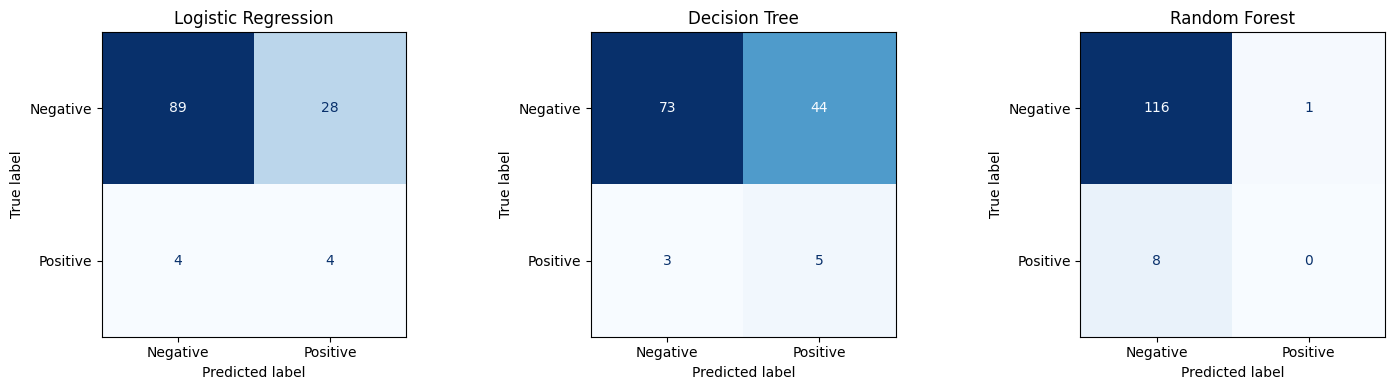

In [39]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, result) in zip(
    axes,
    test_predictions.items()
):

    cm = confusion_matrix(
        y_val,
        result["predictions"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [40]:
for name, result in test_predictions.items():

    print(f"\n{name}")
    print(
        classification_report(
            y_val,
            result["predictions"],
            target_names=["Negative", "Positive"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.96      0.76      0.85       117
    Positive       0.12      0.50      0.20         8

    accuracy                           0.74       125
   macro avg       0.54      0.63      0.52       125
weighted avg       0.90      0.74      0.81       125


Decision Tree
              precision    recall  f1-score   support

    Negative       0.96      0.62      0.76       117
    Positive       0.10      0.62      0.18         8

    accuracy                           0.62       125
   macro avg       0.53      0.62      0.47       125
weighted avg       0.91      0.62      0.72       125


Random Forest
              precision    recall  f1-score   support

    Negative       0.94      0.99      0.96       117
    Positive       0.00      0.00      0.00         8

    accuracy                           0.93       125
   macro avg       0.47      0.50      0.48       125
weighted avg       0.88

Selected model: Random Forest


,Feature,Importance_Mean,Importance_Std
8,Hormonal Contraceptives (years),0.083903,0.016858
2,First sexual intercourse,0.019333,0.030586
11,STDs,0.018613,0.005670
12,STDs (number),0.013505,0.013193
9,IUD,0.012282,0.007428
18,STDs:HIV,0.012216,0.004987
10,IUD (years),0.011360,0.009658
3,Num of pregnancies,0.007215,0.034402
21,STDs: Number of diagnosis,0.005191,0.011144
14,STDs:vaginal condylomatosis,0.000000,0.000000


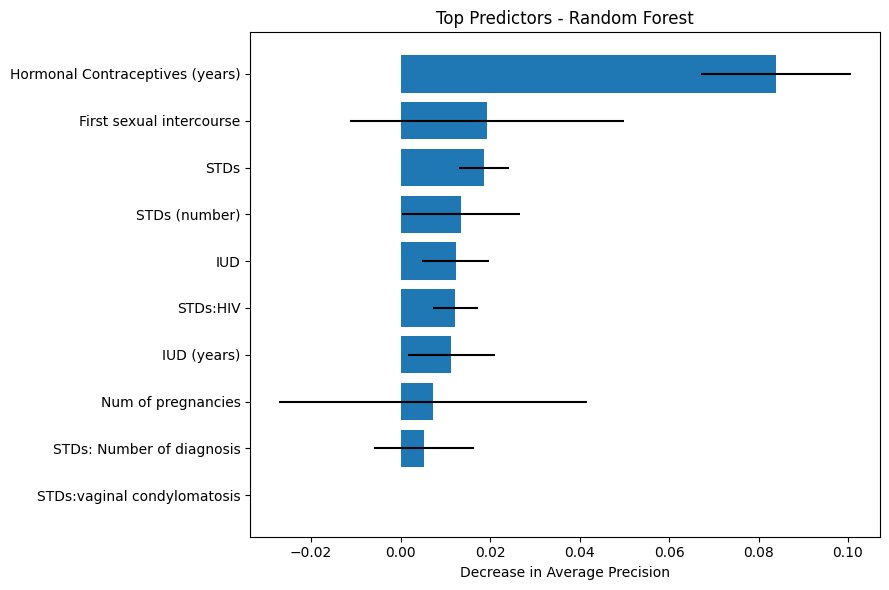

In [41]:

# Select the best model based on cross-validation average precision
best_model_name = tuning_results_df.sort_values(
    "Best CV Average Precision",
    ascending=False
).iloc[0]["Model"]

best_model = best_models[best_model_name]

print("Selected model:", best_model_name)

# Calculate permutation importance on the untouched test set
# Use average precision as the scoring metric
importance = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": importance.importances_mean,
    "Importance_Std": importance.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
)

display(importance_df)

# Visualise the top 10 features
top_features = importance_df.head(10).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"]
)

plt.xlabel("Decrease in Average Precision")
plt.title(f"Top Predictors - {best_model_name}")
plt.tight_layout()
plt.show()


In [42]:

for name, model in best_models.items():

    y_pred = model.predict(X_test)

    print(f"\n{'='*45}")
    print(name)

    print("Test samples:", len(y_test))
    print("Actual positive cases:", (y_test == 1).sum())
    print("Actual negative cases:", (y_test == 0).sum())

    print("Predicted positive cases:", (y_pred == 1).sum())
    print("Predicted negative cases:", (y_pred == 0).sum())

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nAccuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1:", f1_score(y_test, y_pred, zero_division=0))



Logistic Regression
Test samples: 125
Actual positive cases: 8
Actual negative cases: 117
Predicted positive cases: 33
Predicted negative cases: 92

Confusion matrix:
[[87 30]
 [ 5  3]]

Accuracy: 0.72
Precision: 0.09090909090909091
Recall: 0.375
F1: 0.14634146341463414

Decision Tree
Test samples: 125
Actual positive cases: 8
Actual negative cases: 117
Predicted positive cases: 44
Predicted negative cases: 81

Confusion matrix:
[[78 39]
 [ 3  5]]

Accuracy: 0.664
Precision: 0.11363636363636363
Recall: 0.625
F1: 0.19230769230769232

Random Forest
Test samples: 125
Actual positive cases: 8
Actual negative cases: 117
Predicted positive cases: 2
Predicted negative cases: 123

Confusion matrix:
[[116   1]
 [  7   1]]

Accuracy: 0.936
Precision: 0.5
Recall: 0.125
F1: 0.2


In [43]:
for name, model in best_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    print("\n", "=" * 40)
    print(name)

    print("Minimum probability:", y_prob.min())
    print("Maximum probability:", y_prob.max())
    print("Mean probability:", y_prob.mean())

    print("\nProbability distribution:")
    print(pd.Series(y_prob).describe())

    print("\nActual positive cases and their predicted probabilities:")

    results = pd.DataFrame({
        "Actual": y_test,
        "Predicted_Probability": y_prob
    })

    print(
        results[results["Actual"] == 1]
        .sort_values("Predicted_Probability", ascending=False)
    )


Logistic Regression
Minimum probability: 0.15762820374191538
Maximum probability: 0.8294822031235807
Mean probability: 0.452195294317357

Probability distribution:
count    125.000000
mean       0.452195
std        0.120696
min        0.157628
25%        0.380639
50%        0.432476
75%        0.508223
max        0.829482
dtype: float64

Actual positive cases and their predicted probabilities:
     Actual  Predicted_Probability
739       1               0.752976
786       1               0.690383
673       1               0.501604
693       1               0.466658
797       1               0.421661
814       1               0.420534
163       1               0.369113
781       1               0.357771

Decision Tree
Minimum probability: 0.0
Maximum probability: 0.9010884997633699
Mean probability: 0.2514217877432931

Probability distribution:
count    125.000000
mean       0.251422
std        0.351888
min        0.000000
25%        0.000000
50%        0.000000
75%        0.613995
max

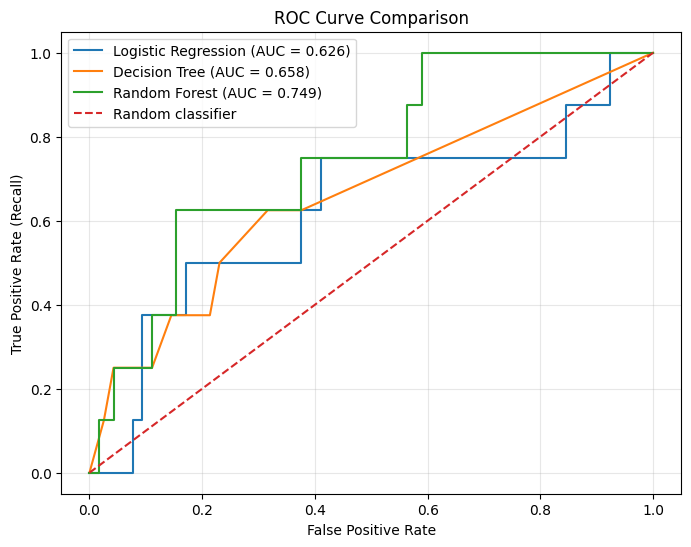

In [44]:

from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, result in test_predictions.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        result["probabilities"]
    )

    auc = roc_auc_score(
        y_val,
        result["probabilities"]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


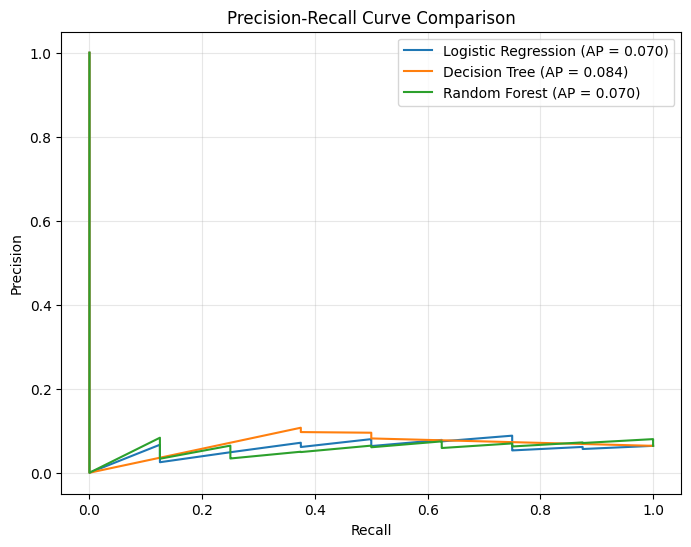

In [45]:

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))

for name, result in test_predictions.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        result["probabilities"]
    )

    ap = average_precision_score(
        y_test,
        result["probabilities"]
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [46]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Select the model with the highest cross-validation
# average precision
best_model_name = tuning_results_df.sort_values(
    "Best CV Average Precision",
    ascending=False
).iloc[0]["Model"]

best_model = best_models[best_model_name]

print("Selected model:", best_model_name)

# Generate probabilities on the validation set
val_probabilities = best_model.predict_proba(X_val)[:, 1]

# Explore thresholds using validation data only
threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


Selected model: Random Forest


,Threshold,Precision,Recall,F1
0,0.10,0.086,0.750,0.154
1,0.15,0.125,0.625,0.208
2,0.20,0.185,0.625,0.286
3,0.25,0.150,0.375,0.214
4,0.30,0.154,0.250,0.190
5,0.35,0.222,0.250,0.235
6,0.40,0.200,0.125,0.154
7,0.45,0.000,0.000,0.000
8,0.50,0.000,0.000,0.000
9,0.55,0.000,0.000,0.000
